In [135]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
from scipy.stats import mode



r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

In [136]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [137]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR+'/Code/DataPrep/concatenated_data_forth_trace.csv',dtype={"value": "float64"})

In [138]:
data.head()

,subject_id,device_id,accelerometer_x,accelerometer_y,accelerometer_z,gyroscope_x,gyroscope_y,gyroscope_z,magnetometer_x,magnetometer_y,magnetometer_z,timestamp,activity_label
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,1
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1


In [139]:
final_columns = [
        "pessoa_x",
        "id_dispositivo",
        "acelerômetro_x",
        "acelerômetro_Y",
        "acelerômetro_Z",
        "giroscópio_x",
        "giroscópio_Y",
        "giroscópio_Z",
        "magnetrômetro_x",
        "magnetrômetro_y",
        "magnetrômetro_z",
        "timestamp",
        "atividade"
    ]

In [140]:
data.columns = final_columns

In [141]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,1
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,1
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,1
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,1
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,1


In [142]:
data.isnull().sum()

pessoa_x           0
id_dispositivo     0
acelerômetro_x     0
acelerômetro_Y     0
acelerômetro_Z     0
giroscópio_x       0
giroscópio_Y       0
giroscópio_Z       0
magnetrômetro_x    0
magnetrômetro_y    0
magnetrômetro_z    0
timestamp          0
atividade          0
dtype: int64

In [143]:
data.shape

(3930873, 13)

In [144]:
#remove the null class
data=data.dropna()

In [145]:
data.shape

(3930873, 13)

In [146]:
data["atividade"].value_counts().sort_index()

atividade
1     805541
2     421504
3     418688
4     699414
5     703766
6     446411
7     223179
8      30976
9      28032
10     29952
11     28160
12     19050
13     38100
14     19050
15      9525
16      9525
Name: count, dtype: int64

In [147]:
data["pessoa_x"].value_counts().sort_index()

pessoa_x
0     265344
1     265216
2     266240
3     266240
4     248704
5     263805
6     267263
7     262397
8     254464
9     260480
10    260864
11    251008
12    265600
13    267008
14    266240
Name: count, dtype: int64

# **Data Exploration**

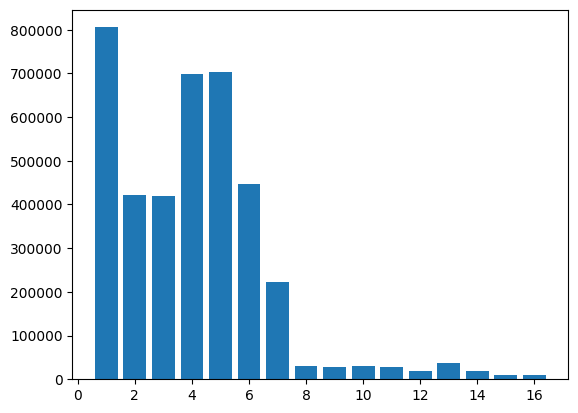

In [148]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

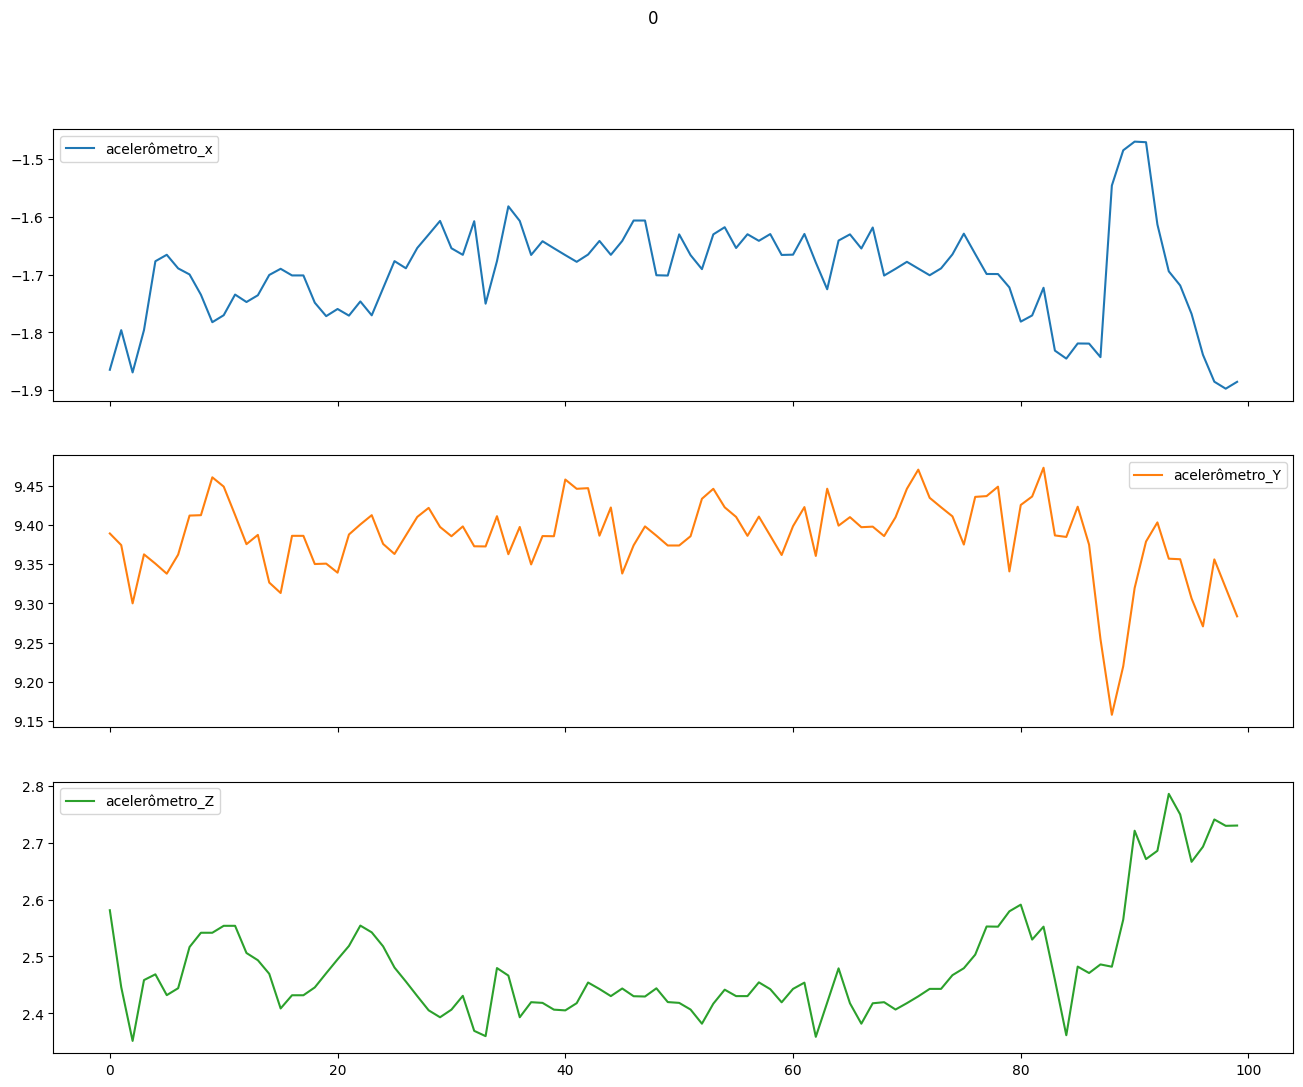

In [149]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:100].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

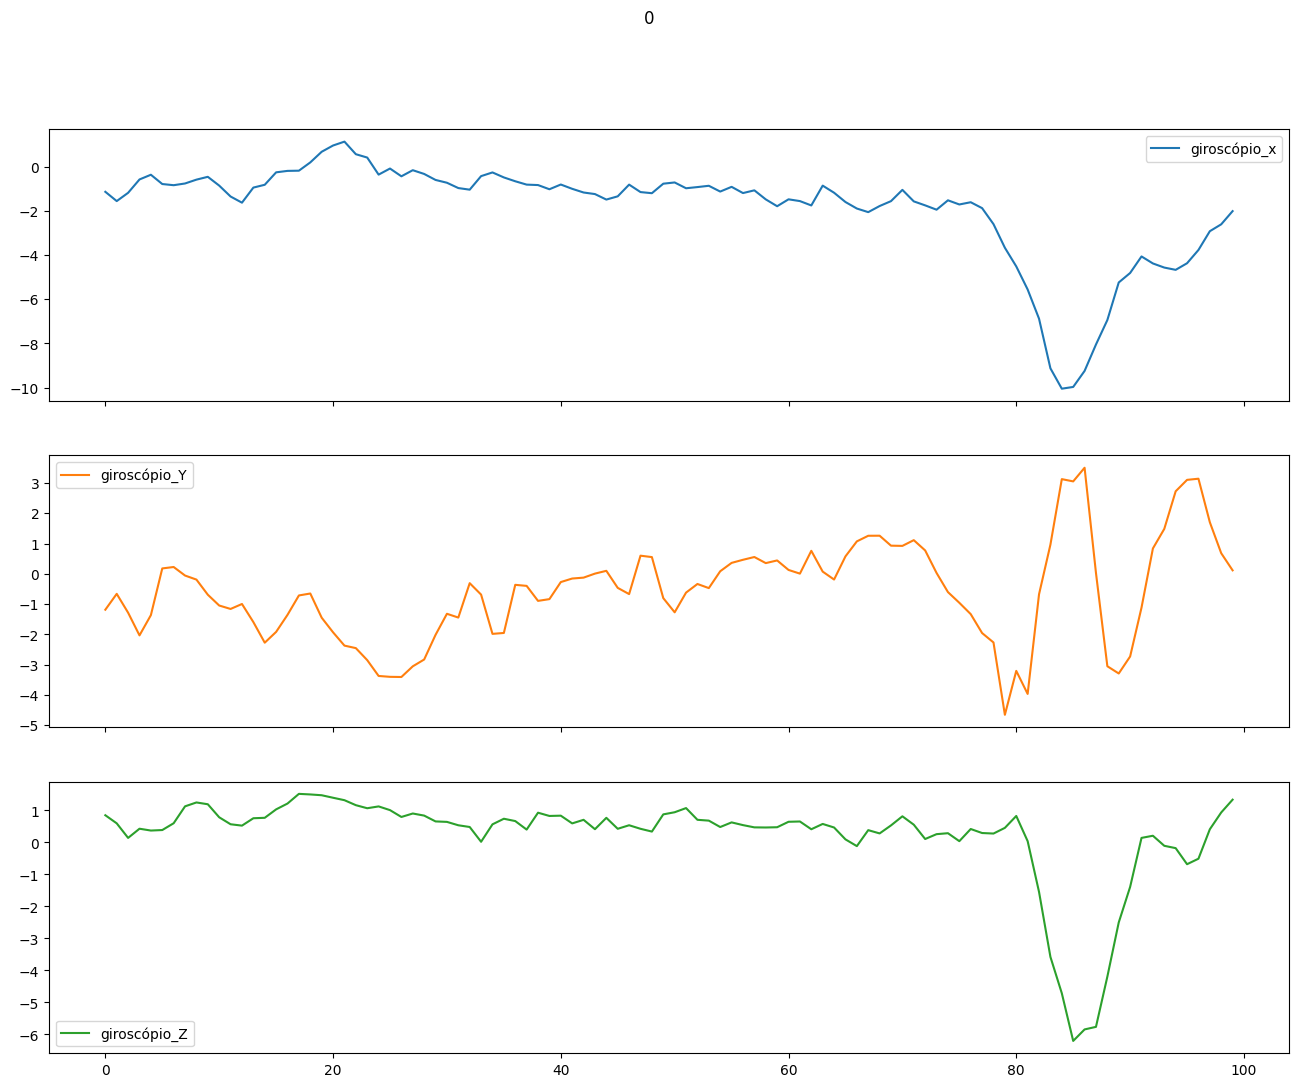

In [150]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:100].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

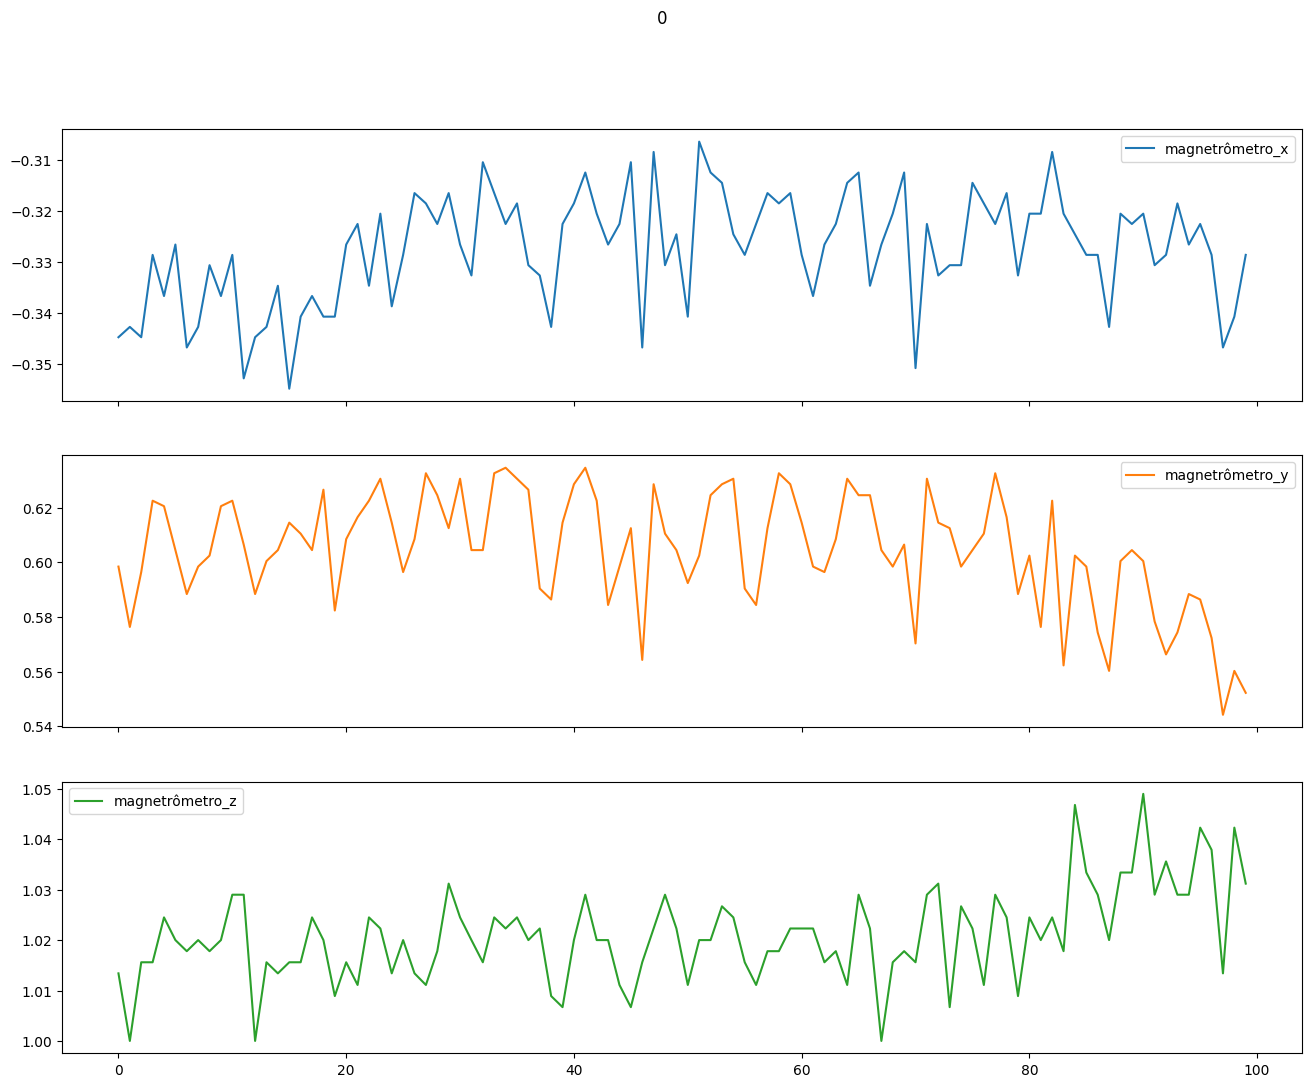

In [151]:
data[(data['atividade'] == 1 )&(data['pessoa_x']==0)][['magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][:100].plot(title='0',subplots=True, figsize=(16, 12))

In [152]:
data.pessoa_x.unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14],
      dtype=int64)

In [153]:
data = data.reset_index(drop=True)

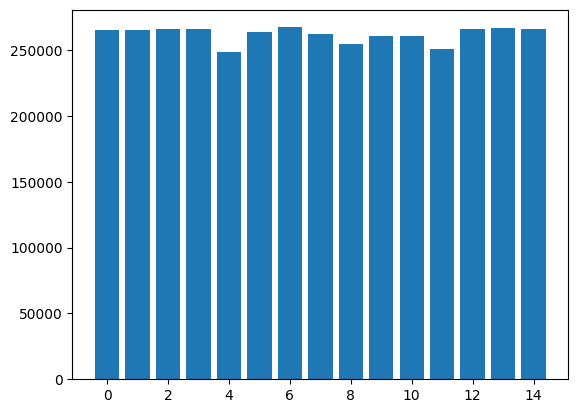

In [154]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [155]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([1,2,4,8,9,12])]

In [156]:
# Define the mapping dictionary
mapping_dict = {1:0,2:1,4:2,8:3,9:4,12:5}

In [157]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [158]:
data.shape

(2004517, 13)

In [159]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [160]:
data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [161]:
data.shape

(2004517, 13)

In [162]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [163]:
print(grouped_data)

atividade      0      1      2     3     4     5
pessoa_x                                        
0          54676  28800  45066  1920  1920  1270
1          52628  28288  48266  2176  1920  1270
2          55956  28416  46346  2048  2048  1270
3          54676  29056  46730  2176  1792  1270
4          51220  26240  44298  2304  1920  1270
5          52369  27904  47114  2176  1920  1270
6          58643  28800  47626  1920  1792  1270
7          50705  28928  46858  1920  1792  1270
8          49940  25600  46858  1792  1792  1270
9          51348  28032  47754  2432  1920  1270
10         57876  28416  46858  2176  1664  1270
11         53652  27136  43530  1920  1664  1270
12         53908  28544  48522  2048  1920  1270
13         54676  28416  46602  2304  1920  1270
14         53268  28928  46986  1664  2048  1270


In [164]:
nan_values = grouped_data[grouped_data.isnull().any(axis=1)].index

In [165]:
nan_values_array = nan_values.to_numpy()

In [166]:
print(nan_values)

Index([], dtype='int64', name='pessoa_x')


In [167]:
#data = data[~data['pessoa_x'].isin([1616, 1618, 1637, 1638, 1640, 1642])]

In [168]:
#grouped_data2 = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [169]:
#print(grouped_data2)

# **Models**

In [170]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [171]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [172]:
""" import numpy as np

# Function to count occurrences of each category
def count_categories(data):
    counts = {
        '[1, 0, 0, 0]': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),
        '[0, 1, 0, 0]': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),
        '[0, 0, 1, 0]': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),
        '[0, 0, 0, 1]': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),
    }
    return counts

# Count categories before removal
print("Category counts before removal:", count_categories(labels_data_categorical))

# Define the desired class count for the first category
desired_class_count = 2151

# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical
first_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]

# Randomly select indices to remove to balance the first class
indices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_count), replace=False)

# Remove the selected indices from both labels_data_categorical and segments_data
labels_data_categorical = np.delete(labels_data_categorical, indices_to_remove, axis=0)
segments_data = np.delete(segments_data, indices_to_remove, axis=0)

# Count categories after removal
print("Category counts after removal:", count_categories(labels_data_categorical))

# Print the shape of the new arrays to verify
print("New shape of labels_data_categorical:", labels_data_categorical.shape)
print("New shape of segments_data:", segments_data.shape)
 """

' import numpy as np\n\n# Function to count occurrences of each category\ndef count_categories(data):\n    counts = {\n        \'[1, 0, 0, 0]\': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),\n        \'[0, 1, 0, 0]\': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),\n        \'[0, 0, 1, 0]\': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),\n        \'[0, 0, 0, 1]\': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),\n    }\n    return counts\n\n# Count categories before removal\nprint("Category counts before removal:", count_categories(labels_data_categorical))\n\n# Define the desired class count for the first category\ndesired_class_count = 2151\n\n# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical\nfirst_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]\n\n# Randomly select indices to remove to balance the first class\nindices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_

In [173]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [174]:
import numpy as np

def normalize_segments_to_mode(df_data_windowed, df_label_windowed):
    # Iterate through each window
    for i in range(df_label_windowed.shape[0]):
        # Get the current window
        window = df_label_windowed[i]
        
        # Replace -1 values with the first value of the window
        first_value = window[0]
        print(first_value)
        window = np.where(window == -1, first_value, window)
        
        # Update the window in the array
        df_label_windowed[i] = window
    
    return df_data_windowed, df_label_windowed


In [175]:
def apply_segmentation_no_sliding_window_validation(df_data):
# Define window size and step size
    window_size = 100
    step_size = 10

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using  window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        first_row_value = df_data[['atividade']].iloc[start_idx, 0]
         # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1        
        ) 
        if label_consistency == True:
            segments[i] = df_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [176]:
def apply_segmentation_no_sliding_window(df_data):
    import numpy as np

    # Define window size and step size
    window_size = 100
    step_size = 10

    # Define the threshold for sufficient transition labels
    transition_threshold = 0.3  # At least 10% of the window size

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1)

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size

        # Get the first row value for label
        first_row_value = df_data[['atividade']].iloc[start_idx, 0]

        # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1
        )

        if label_consistency:
            # Populate the 3D array for consistent labels
            segments[i] = df_data[
                ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                 'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
            ][start_idx:end_idx].values
            targets[i] = df_data[['atividade']][start_idx:end_idx].values
        else:
            # Check for transition labels (values 3, 4, or 5)
            transition_labels = df_data[['atividade']][start_idx:end_idx].isin([3, 4, 5]).values

            # Check if sufficient quantity of transition labels exists
            if transition_labels.sum() >= transition_threshold * window_size:
                # Identify indexes without transition labels
                transition_indexes = np.where(transition_labels)[0]
                non_transition_indexes = np.where(~transition_labels)[0]

                # Set sensor values to zero for non-transition indexes
                for col in ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                            'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                            'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']:
                    df_data[col].iloc[start_idx:end_idx].iloc[non_transition_indexes] = 0

                # Apply the first found transition label to the corresponding targets
                first_transition_value = df_data[['atividade']].iloc[start_idx:end_idx].iloc[transition_indexes[0], 0]
                df_data['atividade'].iloc[start_idx:end_idx].iloc[non_transition_indexes] = first_transition_value

                # Populate the 3D array
                segments[i] = df_data[
                    ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                     'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                     'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
                ][start_idx:end_idx].values
                targets[i] = df_data[['atividade']][start_idx:end_idx].values            

    return segments, targets


In [177]:
def apply_segmentation_with_sliding_window(df_data):
    import numpy as np

    # Define window size and step size
    window_size = 100
    step_size = 10

    # Define the threshold for sufficient transition labels
    transition_threshold = 0.3  # At least 10% of the window size

    # Calculate number of windows
    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1] - 1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1)

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        print(f"end_idx : {end_idx}")
        print(f"df_data.shape[0] : {df_data.shape[0]}")
        if end_idx > df_data.shape[0]:
            print("entrou no continuea")
            continue        

        # Get the first row value for label
        first_row_value = df_data[['atividade']].iloc[start_idx, 0]

        # Label consistency check
        label_consistency = (
            df_data[['atividade']][start_idx:end_idx].nunique()[0] == 1 and
            first_row_value in [3,4,5]
        )
        if label_consistency:
            print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
            # Populate the 3D array for consistent labels
            segments[i] = df_data[
                ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                 'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
            ][start_idx:end_idx].values
            targets[i] = df_data[['atividade']][start_idx:end_idx].values
        else:
            # Check for transition labels (values 3, 4, or 5)
            transition_labels = df_data[['atividade']][start_idx:end_idx].isin([3, 4, 5]).values

            # Check if sufficient quantity of transition labels exists
            if transition_labels.sum() >= transition_threshold * window_size:
                # Identify indexes without transition labels
                transition_indexes = np.where(transition_labels)[0]
                non_transition_indexes = np.where(~transition_labels)[0]

                # Set sensor values to zero for non-transition indexes
                for col in ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                            'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                            'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']:
                    df_data[col].iloc[start_idx:end_idx].iloc[non_transition_indexes] = 0

                # Apply the first found transition label to the corresponding targets
                first_transition_value = df_data[['atividade']].iloc[start_idx:end_idx].iloc[transition_indexes[0], 0]
                df_data['atividade'].iloc[start_idx:end_idx].iloc[non_transition_indexes] = first_transition_value

                # Populate the 3D array
                segments[i] = df_data[
                    ['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z',
                     'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z',
                     'magnetrômetro_x', 'magnetrômetro_y', 'magnetrômetro_z']
                ][start_idx:end_idx].values
                targets[i] = df_data[['atividade']][start_idx:end_idx].values            

    return segments, targets


In [178]:
print(data.pessoa_x.unique())

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [179]:
#X_test_data = data[data['pessoa_x'].isin([0,1])]

In [180]:
#print(X_test_data.shape)

In [181]:
#X_test_data = X_test_data.reset_index(drop = True)

In [182]:
#X_test_data.head()

In [183]:
#X_test_data.tail()

In [184]:
#X_test_data.pessoa_x.unique()

In [185]:
#print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

In [186]:
#X_test_data['atividade'].value_counts()

In [187]:
#X_test_data = X_test_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [188]:
#X_train_validation_data = data[~data.pessoa_x.isin([0,1])]

In [189]:
#print(X_train_validation_data.shape)

In [190]:
#X_train_validation_data = X_train_validation_data.reset_index(drop = True)

In [191]:
#X_train_validation_data.head()

In [192]:
#X_train_validation_data.tail()

In [193]:
#X_train_validation_data.pessoa_x.unique()

In [194]:
#print(f"percentage of validation is {X_train_validation_data.shape[0]/data.shape[0]}")

In [195]:
from imblearn.over_sampling import SMOTE
from collections import Counter
import pandas as pd

def balance_data_with_smote(data, label_column):
    """
    Balances the class distribution in a DataFrame using SMOTE.

    Parameters:
        data (pd.DataFrame): The input DataFrame containing features and labels.
        label_column (str): The name of the column containing class labels.

    Returns:
        pd.DataFrame: A balanced DataFrame with the same structure as the input.
    """
    # Separate features and labels
    X = data.drop(columns=[label_column])
    y = data[label_column]

    # Check class distribution before SMOTE
    print("Before SMOTE:", Counter(y))

    # Apply SMOTE
    smote = SMOTE(sampling_strategy='auto', random_state=42)
    X_smote, y_smote = smote.fit_resample(X, y)

    # Check class distribution after SMOTE
    print("After SMOTE:", Counter(y_smote))

    # Combine features and labels back into a DataFrame
    balanced_data = pd.concat([pd.DataFrame(X_smote, columns=X.columns), 
                               pd.DataFrame(y_smote, columns=[label_column])], axis=1)

    return balanced_data

# Example usage:
# balanced_df = balance_data_with_smote(data, label_column='label')


In [196]:
#X_train_validation_data['atividade'].value_counts()

In [197]:
#X_train_validation_data['atividade'].value_counts()

In [198]:
X_validation_data = data[data['pessoa_x'].isin([11,12,13,14])]

In [199]:
print(X_validation_data.shape)

(534736, 13)


In [200]:
X_validation_data = X_validation_data.reset_index(drop = True)

In [201]:
X_validation_data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,11,1,-2.7330,8.9200,3.2299,-0.754030,-0.93339,-0.090419,-0.67944,0.42369,0.87528,1537.2,0
1,11,1,-2.7328,8.9203,3.2421,-0.334480,-1.81960,0.332430,-0.68548,0.43173,0.88641,1556.7,0
2,11,1,-2.6970,8.8359,3.2431,-0.221800,-2.75300,0.891540,-0.67944,0.42771,0.89310,1576.2,0
3,11,1,-2.6856,8.8234,3.2187,-0.094370,-2.75100,0.962370,-0.68145,0.42570,0.88419,1595.8,0
4,11,1,-2.6616,8.8598,3.2297,0.037206,-2.26130,1.282300,-0.68548,0.40964,0.88864,1615.3,0


In [202]:
X_validation_data.tail()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
534731,14,5,0.042622,9.5341,-2.0574,0.21654,-0.36095,0.52635,-0.19192,0.47106,-0.68913,1042000.0,0
534732,14,5,0.030433,9.5218,-2.0691,0.32055,-0.11574,0.38508,-0.23232,0.50100,-0.68043,1042000.0,0
534733,14,5,0.018118,9.5337,-2.0691,0.23099,-0.28532,0.40054,-0.19798,0.49900,-0.67174,1042000.0,0
534734,14,5,0.017996,9.5458,-2.0693,0.35203,-0.22221,0.45125,-0.20202,0.46906,-0.67391,1042100.0,0
534735,14,5,0.030431,9.5339,-2.0571,0.18366,-0.11540,0.55545,-0.17980,0.49900,-0.68478,1042100.0,0


In [203]:
X_validation_data.pessoa_x.unique()

array([11, 12, 13, 14], dtype=int64)

In [204]:
print(f"percentage of validation is {X_validation_data.shape[0]/data.shape[0]}")

percentage of validation is 0.2667655100954494


In [205]:
X_validation_data['atividade'].value_counts()

atividade
0    215504
2    185640
1    113024
3      7936
4      7552
5      5080
Name: count, dtype: int64

In [206]:
X_validation_data = X_validation_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [207]:
X_train_data = data[~data.pessoa_x.isin([11,12,13,14])]

In [208]:
print(f"percentage of validation is {X_train_data.shape[0]/data.shape[0]}")

percentage of validation is 0.7332344899045505


In [209]:
X_train_data.pessoa_x.unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10], dtype=int64)

In [210]:
X_train_data.shape

(1469781, 13)

In [211]:
X_train_data['atividade'].value_counts()

atividade
0    590037
2    513774
1    308480
3     23040
4     20480
5     13970
Name: count, dtype: int64

In [212]:
#X_train_data = balance_data_with_smote(X_train_data,'atividade')

In [213]:
X_train_data['atividade'].value_counts()

atividade
0    590037
2    513774
1    308480
3     23040
4     20480
5     13970
Name: count, dtype: int64

In [214]:
X_train_data = X_train_data.reset_index(drop=True)

In [215]:
X_train_data.head()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
0,0,1,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,505.89,0
1,0,1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,525.42,0
2,0,1,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,544.95,0
3,0,1,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,564.48,0
4,0,1,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,584.01,0


In [216]:
X_train_data.tail()

,pessoa_x,id_dispositivo,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,timestamp,atividade
1469776,10,5,0.37203,8.8559,-3.9407,-0.11881,-0.28598,0.68444,-0.40808,0.66267,-0.20435,1041600.0,0
1469777,10,5,0.35997,8.8437,-3.9402,-0.17996,-0.25544,0.72973,-0.42626,0.63473,-0.20435,1041600.0,0
1469778,10,5,0.34777,8.8436,-3.9399,-0.16427,-0.30265,0.59747,-0.39798,0.64271,-0.20870,1041600.0,0
1469779,10,5,0.36009,8.8317,-3.9399,-0.14938,-0.27108,0.66963,-0.40202,0.66667,-0.20652,1041600.0,0
1469780,10,5,0.35984,8.8558,-3.9404,-0.19606,-0.16566,0.51419,-0.41212,0.65669,-0.20217,1041600.0,0


In [217]:
X_train_data = X_train_data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','magnetrômetro_x','magnetrômetro_y','magnetrômetro_z','atividade']]

In [218]:
X_train_data.head()

,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,magnetrômetro_x,magnetrômetro_y,magnetrômetro_z,atividade
0,-1.8650,9.3890,2.5812,-1.14180,-1.18560,0.84998,-0.34476,0.59839,1.0134,0
1,-1.7963,9.3742,2.4460,-1.56180,-0.66165,0.59730,-0.34274,0.57631,1.0000,0
2,-1.8696,9.3000,2.3514,-1.18770,-1.28410,0.14212,-0.34476,0.59639,1.0156,0
3,-1.7961,9.3624,2.4584,-0.58399,-2.03340,0.42912,-0.32863,0.62249,1.0156,0
4,-1.6768,9.3506,2.4685,-0.37050,-1.36470,0.37194,-0.33669,0.62048,1.0245,0


In [219]:
""" segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data)
print(targets_test.shape)
print(segments_test.shape) """

' segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data)\nprint(targets_test.shape)\nprint(segments_test.shape) '

In [220]:
""" segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)
print(targets_test.shape)
print(segments_test.shape) """

' segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)\nprint(targets_test.shape)\nprint(segments_test.shape) '

In [221]:
""" targets_test = targets_test.reshape(targets_test.shape[0],100) """

' targets_test = targets_test.reshape(targets_test.shape[0],100) '

In [222]:
""" print(targets_test.shape) """

' print(targets_test.shape) '

In [223]:
""" print(targets_test) """

' print(targets_test) '

In [224]:
""" labels_test = targets_test[:,0] """

' labels_test = targets_test[:,0] '

In [225]:
#print(labels_test)

In [226]:
#print(labels_test.shape)

In [227]:
#labels_test_categorical = to_categorical(labels_test,num_classes=6)

In [228]:
#print(labels_test_categorical)

In [229]:
#print(labels_test_categorical.shape)

In [230]:
#category_count_categorical(labels_test_categorical)

In [231]:
segments_val,targets_val = apply_segmentation_no_sliding_window_validation(X_validation_data)
print(targets_val.shape)
print(segments_val.shape)

(5347, 100, 1)
(5347, 100, 9)


In [232]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 200, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 200, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [233]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 200, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 200, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 200, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 200, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [234]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 100, 1)
# Example: df = np.random.randint(0, 10, size=(10, 200, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 200, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 200, 1))  # 5 windows of 100 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 100, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 200, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 200, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 200, 1))  # 5 windows of 100 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [235]:
segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
print(targets_val.shape)
print(segments_val.shape)

(5133, 100, 1)
(5133, 100, 9)


In [236]:
#segments_val,targets_val = normalize_segments_to_mode(segments_val,targets_val)

In [237]:
""" import numpy as np
from collections import Counter

# Assuming `array` is your 3D array with shape (n, 200, 1)
# Create a sample array for demonstration
n = 10  # Number of windows
array = np.random.randint(0, 10, (n, 250, 1))  # Replace this with your actual array

# Flatten the 3D array into a 1D array
flattened_array = targets_val.flatten()

# Count the unique values
unique_values, counts = np.unique(flattened_array, return_counts=True)

# Combine the results into a dictionary
value_counts = dict(zip(unique_values, counts))

# Display the counts
print("Unique values and their counts:")
for value, count in value_counts.items():
    print(f"Value {value}: Count {count}")
 """

' import numpy as np\nfrom collections import Counter\n\n# Assuming `array` is your 3D array with shape (n, 200, 1)\n# Create a sample array for demonstration\nn = 10  # Number of windows\narray = np.random.randint(0, 10, (n, 250, 1))  # Replace this with your actual array\n\n# Flatten the 3D array into a 1D array\nflattened_array = targets_val.flatten()\n\n# Count the unique values\nunique_values, counts = np.unique(flattened_array, return_counts=True)\n\n# Combine the results into a dictionary\nvalue_counts = dict(zip(unique_values, counts))\n\n# Display the counts\nprint("Unique values and their counts:")\nfor value, count in value_counts.items():\n    print(f"Value {value}: Count {count}")\n '

In [238]:
""" import numpy as np
import pandas as pd

# Assume df is the 3D numpy array of shape (n, 200, 1)
# Example: df = np.random.randint(0, 10, size=(10, 200, 1))

def count_unique_values_per_window(df):
    # Ensure the input is 3D
    if df.ndim != 3 or df.shape[2] != 1:
        raise ValueError("Input must be a 3D array of shape (n, 200, 1)")
    
    # Reshape the third dimension for easier processing
    reshaped_df = df.reshape(df.shape[0], df.shape[1])

    # List to store counts for each window
    unique_counts = []

    for window in reshaped_df:
        # Count unique values and their frequencies
        unique, counts = np.unique(window, return_counts=True)
        unique_counts.append(dict(zip(unique, counts)))

    return unique_counts

# Example usage
#df = np.random.randint(0, 10, size=(5, 200, 1))  # 5 windows of 200 rows with random integers 0-9
result = count_unique_values_per_window(targets_val)

# Convert the result to a DataFrame for better visualization
result_df = pd.DataFrame(result).fillna(0).astype(int)

# Display the result
print(result_df)
 """

' import numpy as np\nimport pandas as pd\n\n# Assume df is the 3D numpy array of shape (n, 200, 1)\n# Example: df = np.random.randint(0, 10, size=(10, 200, 1))\n\ndef count_unique_values_per_window(df):\n    # Ensure the input is 3D\n    if df.ndim != 3 or df.shape[2] != 1:\n        raise ValueError("Input must be a 3D array of shape (n, 200, 1)")\n    \n    # Reshape the third dimension for easier processing\n    reshaped_df = df.reshape(df.shape[0], df.shape[1])\n\n    # List to store counts for each window\n    unique_counts = []\n\n    for window in reshaped_df:\n        # Count unique values and their frequencies\n        unique, counts = np.unique(window, return_counts=True)\n        unique_counts.append(dict(zip(unique, counts)))\n\n    return unique_counts\n\n# Example usage\n#df = np.random.randint(0, 10, size=(5, 200, 1))  # 5 windows of 200 rows with random integers 0-9\nresult = count_unique_values_per_window(targets_val)\n\n# Convert the result to a DataFrame for better v

In [239]:
""" import numpy as np

# Example 3D array (replace with your actual array)
n = 10
array = np.random.randint(-5, 5, (n, 200, 1))  # Replace with your actual array

# Check if the last dimension has any value = -1
has_minus_one = np.any(targets_val[:, :, 0] == 5)

if has_minus_one:
    print("The array contains at least one -1 in the last dimension.")
else:
    print("The array does not contain any -1 in the last dimension.")
 """

' import numpy as np\n\n# Example 3D array (replace with your actual array)\nn = 10\narray = np.random.randint(-5, 5, (n, 200, 1))  # Replace with your actual array\n\n# Check if the last dimension has any value = -1\nhas_minus_one = np.any(targets_val[:, :, 0] == 5)\n\nif has_minus_one:\n    print("The array contains at least one -1 in the last dimension.")\nelse:\n    print("The array does not contain any -1 in the last dimension.")\n '

In [240]:
targets_val = targets_val.reshape(targets_val.shape[0],100)

In [241]:
print(targets_val.shape)

(5133, 100)


In [242]:
count_active_classes(targets_val)

{0: 2081, 100: 1107, 200: 1818, 300: 61, 400: 58, 500: 8}

In [243]:
print(targets_val)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [244]:
labels_val = targets_val[:,0]

In [245]:
print(labels_val)

[0 0 0 ... 0 0 0]


In [246]:
print(labels_val.shape)

(5133,)


In [247]:
labels_val_categorical = to_categorical(labels_val,num_classes=6)

In [248]:
print(labels_val_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]


In [249]:
print(labels_val_categorical.shape)

(5133, 6)


In [250]:
category_count_categorical(labels_val_categorical)

Category counts: [2081. 1107. 1818.   61.   58.    8.]


In [251]:
X_train_data['atividade'].value_counts()

atividade
0    590037
2    513774
1    308480
3     23040
4     20480
5     13970
Name: count, dtype: int64

In [252]:
import numpy as np

def augment_data_crop(variable_data, label_data, crop_size=90):
    """
    Augments data using random cropping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        crop_size (int): Size of the cropped window. Defaults to 90.

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """
    def random_crop(window, crop_size=90):
        """
        Perform random cropping on a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            crop_size (int): Size of the cropped window.
        Returns:
            np.array: Cropped window with shape (100, 7).
        """
        start_idx = np.random.randint(0, window.shape[0] - crop_size + 1)
        return np.pad(window[start_idx:start_idx + crop_size], 
                      ((0, 100 - crop_size), (0, 0)), mode='constant')

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 14
            elif label == 4:
                synthetic_count = 16
            elif label == 5:
                synthetic_count = 20
            else:
                synthetic_count = 0
            
            # Generate synthetic windows
            for _ in range(synthetic_count):
                synthetic_window = random_crop(var_window, crop_size)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (1000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [253]:
import numpy as np
from scipy.interpolate import interp1d

def augment_data_with_time_warping(variable_data, label_data, warp_range=(0.95, 1.10)):
    """
    Augments data using Time Warping for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        warp_range (tuple): Range for time compression/stretching (default is ±5%-10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def time_warp(window, warp_factor):
        """
        Apply time warping to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            warp_factor (float): Factor to compress/stretch time.
        Returns:
            np.array: Time-warped window with shape (100, 7).
        """
        original_time = np.linspace(0, 1, window.shape[0])
        warped_time = np.linspace(0, 1, max(2, int(window.shape[0] * warp_factor)))  # Ensure at least 2 points

        # Interpolate each feature column separately
        interpolated_window = []
        for i in range(window.shape[1]):  # Iterate over each feature (axis=1)
            interpolator = interp1d(warped_time, 
                                    np.interp(warped_time, original_time, window[:, i]), 
                                    kind='linear', 
                                    fill_value="extrapolate", 
                                    bounds_error=False)
            interpolated_window.append(interpolator(original_time))

        return np.stack(interpolated_window, axis=1)



    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 28
            elif label == 4:
                synthetic_count = 34
            elif label == 5:
                synthetic_count = 30
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using Time Warping
            for _ in range(synthetic_count):
                warp_factor = np.random.uniform(*warp_range)
                synthetic_window = time_warp(var_window, warp_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data

# Example usage:
# variable_data = np.random.rand(1000, 100, 7)  # Replace with actual data
# label_data = np.random.randint(0, 6, (1000, 100, 1))  # Replace with actual data
# augmented_var, augmented_labels = augment_data_with_time_warping(variable_data, label_data)
# print("Augmented Variable Data Shape:", augmented_var.shape)
# print("Augmented Label Data Shape:", augmented_labels.shape)


In [254]:
import numpy as np

def augment_data_with_magnitude_scaling(variable_data, label_data, scale_range=(0.9, 1.1)):
    """
    Augments data using magnitude scaling for windows with unique labels 3, 4, or 5.

    Args:
        variable_data (np.array): 3D array of variable data with shape (n, 100, 7).
        label_data (np.array): 2D array of label data with shape (n, 100, 1).
        scale_range (tuple): Range for scaling magnitude (default is ±10%).

    Returns:
        tuple: Augmented variable data and label data as separate arrays.
    """

    def magnitude_scaling(window, scale_factor):
        """
        Apply magnitude scaling to a given window.
        Args:
            window (np.array): Input window with shape (100, 7).
            scale_factor (float): Factor to scale magnitudes.
        Returns:
            np.array: Scaled window with shape (100, 7).
        """
        return window * scale_factor

    # Step 1: Zip the two arrays
    zipped_data = list(zip(variable_data, label_data))

    # To hold augmented data
    augmented_variable_data = []
    augmented_label_data = []

    # Step 2, 3, 4, 5: Iterate through each window and perform operations
    for var_window, label_window in zipped_data:
        # Check if label in window is unique
        unique_labels = np.unique(label_window)
        if len(unique_labels) == 1:
            label = unique_labels[0]  # Unique label
            augmented_variable_data.append(var_window)
            augmented_label_data.append(label_window)
            
            # Define number of synthetic windows based on label
            if label == 3:
                synthetic_count = 10
            elif label == 4:
                synthetic_count = 10
            elif label == 5:
                synthetic_count = 20
            else:
                synthetic_count = 0
            
            # Generate synthetic windows using magnitude scaling
            for _ in range(synthetic_count):
                scale_factor = np.random.uniform(*scale_range)
                synthetic_window = magnitude_scaling(var_window, scale_factor)
                augmented_variable_data.append(synthetic_window)
                augmented_label_data.append(label_window)  # Use the same label window

    # Step 6: Unzip the augmented arrays
    augmented_variable_data = np.array(augmented_variable_data)
    augmented_label_data = np.array(augmented_label_data)

    return augmented_variable_data, augmented_label_data


In [255]:
#print(occurrence_transitions_slide)

In [256]:
X_train_data_transitions = X_train_data[~X_train_data.atividade.isin([0,1,2])]

In [257]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 200, 1)
    #data = np.random.randint(0, 3, (256, 250, 1))

    # Reshape to (256, 200) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 100)

    # Get unique values per window (each window has 200 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [258]:
segments_train_transitions,targets_train_transitions = apply_segmentation_with_sliding_window(X_train_data_transitions)

end_idx : 100
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 200
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 300
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 400
df_data.shape[0] : 57490
end_idx : 500
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 600
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 700
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 800
df_data.shape[0] : 57490
end_idx : 900
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 1000
df_data.shape[0] : 57490
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
end_idx : 1100
df_data.shape[0] : 57490
end_idx : 1200
df_data.sh

In [259]:
occurrence_transitions= ocurrence_unique_values(targets_train_transitions)

In [260]:
print(occurrence_transitions)

{-1: 5166, 3: 233, 4: 206, 5: 135}


In [261]:
targets_train_transitions.shape

(5740, 100, 1)

In [262]:
segments_train_transitions_no_sliding,targets_train_transitions_no_sliding = apply_segmentation_no_sliding_window(X_train_data_transitions)

In [263]:
occurrence_transitions_slide= ocurrence_unique_values(targets_train_transitions_no_sliding)

In [264]:
print(occurrence_transitions_slide)

{3: 233, 4: 206, 5: 135}


In [265]:
targets_train_transitions_no_sliding.shape

(574, 100, 1)

In [266]:
X_train_data_atomic = X_train_data[X_train_data.atividade.isin([0,1,2])]

In [267]:
segments_train_atomic,targets_train_atomic = apply_segmentation_no_sliding_window(X_train_data_atomic)

In [268]:
print(segments_train_atomic.shape)

(14122, 100, 9)


In [269]:
print(targets_train_atomic.shape)

(14122, 100, 1)


In [270]:
segments_train = np.vstack((segments_train_atomic,segments_train_transitions))

In [271]:
targets_train = np.vstack((targets_train_atomic,targets_train_transitions))

In [272]:
print(segments_train.shape)

(19862, 100, 9)


In [273]:
print(targets_train.shape)

(19862, 100, 1)


In [274]:
segments_train_crop,targets_train_crop = augment_data_crop(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [275]:
occurrence_crop = ocurrence_unique_values(targets_train_crop)

In [276]:
print(occurrence_crop)

{3: 2670, 4: 2567, 5: 1701}


In [277]:
print(segments_train_crop.shape)

(6938, 100, 9)


In [278]:
print(targets_train_crop.shape)

(6938, 100, 1)


In [279]:
segments_train = np.vstack((segments_train,segments_train_crop))

In [280]:
targets_train = np.vstack((targets_train,targets_train_crop))

In [281]:
print(segments_train.shape)

(26800, 100, 9)


In [282]:
print(targets_train.shape)

(26800, 100, 1)


In [283]:
segments_train_time_warping, targets_train_time_warping = augment_data_with_time_warping(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [284]:
print(segments_train_time_warping.shape)

(12958, 100, 9)


In [285]:
print(targets_train_time_warping.shape)

(12958, 100, 1)


In [286]:
occurrence_time_warping = ocurrence_unique_values(targets_train_time_warping)

In [287]:
print(occurrence_time_warping)

{3: 5162, 4: 5285, 5: 2511}


In [288]:
segments_train = np.vstack((segments_train,segments_train_time_warping))

In [289]:
targets_train = np.vstack((targets_train,targets_train_time_warping))

In [290]:
print(segments_train.shape)

(39758, 100, 9)


In [291]:
print(targets_train.shape)

(39758, 100, 1)


In [292]:
segments_train_magnitude_scaling,target_trains_magnitude_scaling = augment_data_with_magnitude_scaling(segments_train_transitions_no_sliding,targets_train_transitions_no_sliding)

In [293]:
occurrence_magnitude_scaling = ocurrence_unique_values(target_trains_magnitude_scaling)

In [294]:
print(occurrence_magnitude_scaling)

{3: 1958, 4: 1661, 5: 1701}


In [295]:
print(segments_train_magnitude_scaling.shape)

(5320, 100, 9)


In [296]:
print(target_trains_magnitude_scaling.shape)

(5320, 100, 1)


In [297]:
#target_trains_magnitude_scaling = target_trains_magnitude_scaling.reshape(target_trains_magnitude_scaling.shape[0],100)

In [298]:
segments_train = np.vstack((segments_train,segments_train_magnitude_scaling))

In [299]:
targets_train = np.vstack((targets_train,target_trains_magnitude_scaling))

In [300]:
print(segments_train.shape)
print(targets_train.shape)

(45078, 100, 9)
(45078, 100, 1)


In [301]:
#segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)

In [302]:
print(segments_train.shape)
print(targets_train.shape)

(45078, 100, 9)
(45078, 100, 1)


In [303]:
targets_train = targets_train.reshape(targets_train.shape[0],100)

In [304]:
print(targets_train.shape)

(45078, 100)


In [305]:
labels_train = targets_train[:,0]

In [306]:
labels_train_categorical = to_categorical(labels_train,num_classes=6)

In [307]:
print(labels_train_categorical)

[[1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]]


In [308]:
category_count_categorical(labels_train_categorical)

Category counts: [ 5731.  3034.  5031. 10023.  9719. 11540.]


In [309]:
X_train = segments_train
y_train = labels_train_categorical
X_validation = segments_val
y_validation = labels_val_categorical

In [310]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(45078, 100, 9)
(45078, 6)
(5133, 100, 9)
(5133, 6)


In [311]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [312]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [313]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(45078, 100, 9)
(45078, 6)
(5133, 100, 9)
(5133, 6)


In [314]:
#from tensorflow.keras import regularizers

In [315]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [316]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Attention
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(100, 9))
    
    # LSTM layer
    lstm_out = LSTM(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), 
                    kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
                    return_sequences=True)(inputs)
    
    
    dense_out = Dense(hp.Int("input_units_lstm1", min_value=32, max_value=256, step=32), activation='relu')(lstm_out)
    # Attention mechanism using Keras Attention layer
    attention = Attention()([dense_out, dense_out])
    
    # Context vector computation
    context_vector = tf.reduce_sum(attention, axis=1)
    
    # Output layer
    output = Dense(6, activation='softmax')(context_vector)
    
    # Model definition
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', 
                  optimizer=tf.keras.optimizers.Adam(hp.Float('learning_rate', 
                                                              min_value=1e-4, 
                                                              max_value=1e-2, 
                                                              sampling='LOG', 
                                                              default=1e-3)),
                  metrics=['accuracy'])
    
    return model


In [317]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(6, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(200,6))\n    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n             recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),return_sequences=True)(inputs)\n    \n    # Attention mechanism\n    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation=\'relu\')(lstm_out)    \n    attention = Permute([2, 1])(attention)\n    attention = Activation(\'softmax\')(attention)\n    attention = Permute([2, 1])(attention)\n    \n    context_vector = Multiply()([lstm_out, attention])\n    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    \n    output

In [318]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [319]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [320]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 5 Complete [03h 16m 40s]
val_accuracy: 0.863822340965271

Best val_accuracy So Far: 0.863822340965271
Total elapsed time: 06h 32m 52s


In [321]:
tuner.results_summary()

Results summary
Results in C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro/Code/DataPrep/2024-11-19_21-37-46\lstm_acel_giro_multiclass
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 4 summary
Hyperparameters:
input_units_lstm1: 256
l2_reg1: 0.0015159319577885927
learning_rate: 0.008547485565344062
Score: 0.863822340965271

Trial 2 summary
Hyperparameters:
input_units_lstm1: 160
l2_reg1: 0.0013607174450468629
learning_rate: 0.0009887195863122636
Score: 0.8468731641769409

Trial 0 summary
Hyperparameters:
input_units_lstm1: 192
l2_reg1: 0.0011942731780421024
learning_rate: 0.0006562536901904111
Score: 0.8402493596076965

Trial 1 summary
Hyperparameters:
input_units_lstm1: 96
l2_reg1: 0.05977728042983696
learning_rate: 0.000505466655750672
Score: 0.8005065321922302

Trial 3 summary
Hyperparameters:
input_units_lstm1: 64
l2_reg1: 0.0905127409782462
learning_rate: 0.001715074355925934
Score: 0.8001168966293335


In [322]:
tuner.get_best_hyperparameters()[0].values

{'input_units_lstm1': 256,
 'l2_reg1': 0.0015159319577885927,
 'learning_rate': 0.008547485565344062}

In [323]:
best_model = tuner.get_best_models(num_models=1)[0]

In [324]:
best_model.history

In [325]:
best_model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 100, 9)]             0         []                            
                                                                                                  
 lstm (LSTM)                 (None, 100, 256)             272384    ['input_1[0][0]']             
                                                                                                  
 dense (Dense)               (None, 100, 256)             65792     ['lstm[0][0]']                
                                                                                                  
 attention (Attention)       (None, 100, 256)             0         ['dense[0][0]',               
                                                                     'dense[0][0]']           

In [326]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

161/161 [==============================] - 20s 122ms/step - loss: 0.7530 - accuracy: 0.8638


In [327]:
predictions = best_model.predict(X_validation)

161/161 [==============================] - 21s 128ms/step


In [328]:
print(y_validation)

[[0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]
 ...
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0.]]


In [329]:
print(y_validation.shape)

(5133, 6)


In [330]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [331]:
print(y_validation_inverse)

[1 2 0 ... 2 2 2]


In [332]:
print(len(y_validation_inverse))

5133


In [333]:
print(predictions)

[[3.9155637e-03 9.7842902e-01 9.0723219e-08 1.7590724e-02 5.7052087e-09
  6.4663785e-05]
 [2.5283667e-01 4.2938087e-13 7.4716246e-01 8.2779413e-16 6.8208308e-12
  9.0504642e-07]
 [9.8595423e-01 5.6528808e-16 7.6101955e-08 2.3067942e-04 8.3406816e-11
  1.3814938e-02]
 ...
 [2.5116123e-10 2.9457613e-26 9.9479985e-01 7.3061800e-12 8.5290173e-14
  5.2001863e-03]
 [1.7604414e-04 1.6055676e-16 9.9977261e-01 6.4727744e-11 5.0222938e-05
  1.0951049e-06]
 [9.4145797e-08 9.8612297e-25 9.9999976e-01 1.4271996e-12 1.2784805e-07
  1.2524862e-10]]


In [334]:
classes_x=np.argmax(predictions,axis=1)

In [335]:
print(classes_x)

[1 2 0 ... 2 2 2]


In [336]:
print(len(classes_x))

5133


In [337]:
print(classes_x.shape)

(5133,)


In [338]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [339]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

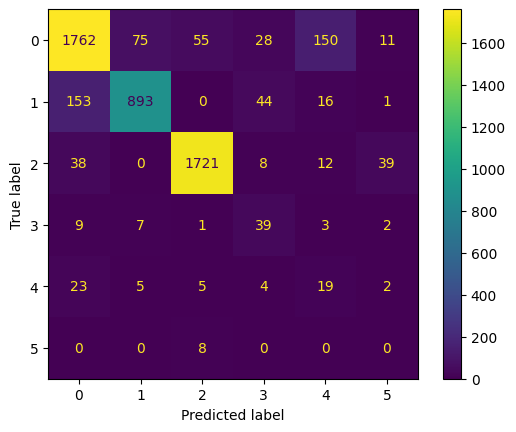

In [340]:
disp.plot()

In [341]:
print(classification_report(y_validation_inverse, classes_x))

              precision    recall  f1-score   support

           0       0.89      0.85      0.87      2081
           1       0.91      0.81      0.86      1107
           2       0.96      0.95      0.95      1818
           3       0.32      0.64      0.42        61
           4       0.10      0.33      0.15        58
           5       0.00      0.00      0.00         8

    accuracy                           0.86      5133
   macro avg       0.53      0.59      0.54      5133
weighted avg       0.90      0.86      0.88      5133



In [ ]:
print(segments_test)

In [ ]:
print(labels_test_categorical.shape)

In [ ]:
print(labels_test_categorical)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, labels_test_categorical)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)